# Customer Feedback: Sentiment + Intent

**Problem:** A support queue gets thousands of messages a day. Tagging each one with sentiment (positive / negative) and a routing intent (complaint, inquiry, praise, suggestion, feedback) is a cheap way to prioritize and triage.

**Data:** `../../data/feedback/`
- `customer_feedback.csv` (5k rows) carries both `sentiment` and `intent` labels. This is the only file we can train both tasks on.
- `amazon_reviews.csv` and `yelp_reviews.csv` carry a binary `label` only (no intent). I run a quick out-of-domain sanity check on these with the TF-IDF sentiment model at the end.

**Approach:** Two passes.
1. A linear TF-IDF baseline (logistic regression) for both heads. Runs on CPU in seconds, gives an honest floor.
2. A multi-task RoBERTa scaffold (shared encoder, two heads). The training loop is gated on `cuda` because fine-tuning 124M params on CPU is not realistic in a notebook.

No cached scores. The numbers printed are whatever this run produced.

In [1]:
# !pip install transformers datasets -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import Dataset as TorchDataset, DataLoader
from transformers import RobertaTokenizer, RobertaModel, get_linear_schedule_with_warmup
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import train_test_split

np.random.seed(7)
torch.manual_seed(7)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

DATA_DIR = Path("../../data/feedback")
assert DATA_DIR.exists(), "Add customer feedback data to data/feedback/"

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

Device: cpu


In [3]:
# Only customer_feedback.csv carries both labels. The Amazon/Yelp files have a binary
# "label" column and no intent, so naively concat'ing them would leave 20k NaN rows.
fb = pd.read_csv(DATA_DIR / "customer_feedback.csv")
fb = fb.dropna(subset=["text", "sentiment", "intent"]).reset_index(drop=True)

text_col, sent_col, intent_col = "text", "sentiment", "intent"
print(f"Multi-task subset: {len(fb)} rows")
print("Sentiment counts:\n", fb[sent_col].value_counts())
print("\nIntent counts:\n", fb[intent_col].value_counts())
fb.head(2)

Multi-task subset: 5000 rows
Sentiment counts:
 sentiment
negative    2632
positive    2368
Name: count, dtype: int64

Intent counts:
 intent
praise        2386
feedback      1242
inquiry        838
complaint      353
suggestion     181
Name: count, dtype: int64


,text,sentiment,intent
0,Nice clean airport from what I could see. We ...,positive,feedback
1,A disappointing experience! I have been to Roc...,negative,praise


## EDA + a label-noise sanity check

The intent labels in `customer_feedback.csv` look like they were applied with a pretty loose mapping. There are plenty of clearly-negative rants tagged `praise`. Worth knowing before reading the intent F1 below.

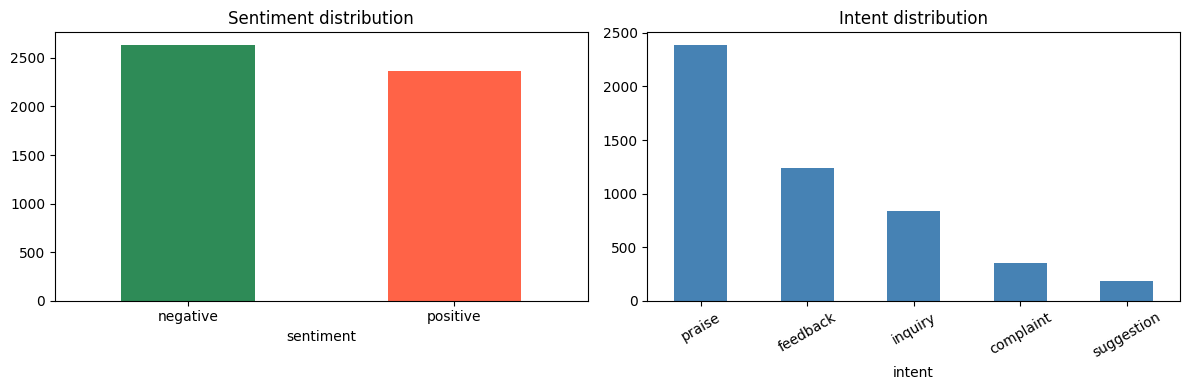

Negative-but-labeled-praise rows: 780 (15.6%)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fb[sent_col].value_counts().plot(kind="bar", ax=axes[0], color=["seagreen", "tomato"])
axes[0].set_title("Sentiment distribution")
axes[0].tick_params(axis="x", rotation=0)

fb[intent_col].value_counts().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Intent distribution")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(ARTIFACTS / "feedback_eda.png", dpi=120)
plt.show()

# quick label-noise spot check: a "negative" labeled "praise" feels off — count it.
maybe_odd = ((fb[sent_col] == "negative") & (fb[intent_col] == "praise")).sum()
print(f"Negative-but-labeled-praise rows: {maybe_odd} ({maybe_odd / len(fb):.1%})")

## TF-IDF + logistic regression baseline (runs on CPU)

Cheap to fit, gives a real number on the same train/test split as the heavier model.

In [5]:
sent_enc = LabelEncoder()
intent_enc = LabelEncoder()

fb["sent_label"]   = sent_enc.fit_transform(fb[sent_col])
fb["intent_label"] = intent_enc.fit_transform(fb[intent_col])
num_sent   = len(sent_enc.classes_)
num_intent = len(intent_enc.classes_)
print(f"Sentiment classes ({num_sent}): {list(sent_enc.classes_)}")
print(f"Intent classes ({num_intent}): {list(intent_enc.classes_)}")

train_df, test_df = train_test_split(fb, test_size=0.2, random_state=7, stratify=fb["sent_label"])
print(f"Train: {len(train_df)}  Test: {len(test_df)}")

vec = TfidfVectorizer(min_df=2, max_df=0.95, ngram_range=(1, 2), max_features=30_000)
Xtr = vec.fit_transform(train_df[text_col].astype(str))
Xte = vec.transform(test_df[text_col].astype(str))

clf_sent = LogisticRegression(max_iter=2000, n_jobs=-1).fit(Xtr, train_df["sent_label"])
clf_int  = LogisticRegression(max_iter=2000, n_jobs=-1).fit(Xtr, train_df["intent_label"])

f1_sent_lr = f1_score(test_df["sent_label"], clf_sent.predict(Xte), average="macro")
f1_int_lr  = f1_score(test_df["intent_label"], clf_int.predict(Xte), average="macro")
print(f"TF-IDF + LR  sentiment macro-F1: {f1_sent_lr:.3f}")
print(f"TF-IDF + LR  intent    macro-F1: {f1_int_lr:.3f}")
print("\nIntent report:")
print(classification_report(test_df["intent_label"], clf_int.predict(Xte), target_names=intent_enc.classes_, zero_division=0))

Sentiment classes (2): ['negative', 'positive']
Intent classes (5): ['complaint', 'feedback', 'inquiry', 'praise', 'suggestion']
Train: 4000  Test: 1000


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


TF-IDF + LR  sentiment macro-F1: 0.888
TF-IDF + LR  intent    macro-F1: 0.388

Intent report:
              precision    recall  f1-score   support

   complaint       1.00      0.10      0.19        68
    feedback       0.70      0.66      0.68       249
     inquiry       0.64      0.20      0.30       174
      praise       0.65      0.96      0.77       475
  suggestion       0.00      0.00      0.00        34

    accuracy                           0.66      1000
   macro avg       0.60      0.38      0.39      1000
weighted avg       0.66      0.66      0.60      1000



In [6]:
tokenizer = RobertaTokenizer.from_pretrained("roberta-base")

class FeedbackDataset(TorchDataset):
    def __init__(self, texts, sent_labels, intent_labels, tokenizer, max_len=128):
        self.texts = list(texts)
        self.sent_labels = list(sent_labels)
        self.intent_labels = list(intent_labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            str(self.texts[idx]), max_length=self.max_len,
            padding="max_length", truncation=True, return_tensors="pt"
        )
        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "sent_label":     torch.tensor(self.sent_labels[idx], dtype=torch.long),
            "intent_label":   torch.tensor(self.intent_labels[idx], dtype=torch.long),
        }

class MultiTaskRoberta(nn.Module):
    def __init__(self, num_sent, num_intent, dropout=0.1):
        super().__init__()
        self.roberta = RobertaModel.from_pretrained("roberta-base")
        self.drop = nn.Dropout(dropout)
        hidden = self.roberta.config.hidden_size
        self.sentiment_head = nn.Linear(hidden, num_sent)
        self.intent_head    = nn.Linear(hidden, num_intent)

    def forward(self, input_ids, attention_mask):
        out = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        cls = self.drop(out.last_hidden_state[:, 0, :])
        return self.sentiment_head(cls), self.intent_head(cls)

model = MultiTaskRoberta(num_sent, num_intent).to(device)
print("Model parameters:", sum(p.numel() for p in model.parameters()) // 1_000_000, "M")

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model parameters: 124 M


In [7]:
train_ds = FeedbackDataset(
    train_df[text_col], train_df["sent_label"], train_df["intent_label"], tokenizer
)
test_ds = FeedbackDataset(
    test_df[text_col], test_df["sent_label"], test_df["intent_label"], tokenizer
)

# num_workers=0 keeps this safe in notebooks on macOS
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=0)

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=100, num_training_steps=len(train_loader) * 3)
criterion = nn.CrossEntropyLoss()

print(f"Train batches: {len(train_loader)}  |  Test batches: {len(test_loader)}")

Train batches: 125  |  Test batches: 16


In [8]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    sp, sl, ip, il = [], [], [], []
    for batch in loader:
        s_logits, i_logits = model(batch["input_ids"].to(device), batch["attention_mask"].to(device))
        sp.extend(s_logits.argmax(-1).cpu().tolist())
        ip.extend(i_logits.argmax(-1).cpu().tolist())
        sl.extend(batch["sent_label"].tolist())
        il.extend(batch["intent_label"].tolist())
    return (
        f1_score(sl, sp, average="macro"),
        f1_score(il, ip, average="macro"),
    )

if device.type == "cuda":
    EPOCHS = 3
    for epoch in range(EPOCHS):
        model.train()
        total = 0.0
        for batch in train_loader:
            optimizer.zero_grad()
            s_logits, i_logits = model(
                batch["input_ids"].to(device),
                batch["attention_mask"].to(device),
            )
            loss = (
                criterion(s_logits, batch["sent_label"].to(device))
                + criterion(i_logits, batch["intent_label"].to(device))
            )
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            total += loss.item()
        print(f"Epoch {epoch + 1}  train loss: {total / len(train_loader):.4f}")

    f1_sent_rb, f1_int_rb = evaluate(model, test_loader)
    print(f"\nRoBERTa multi-task  sentiment macro-F1: {f1_sent_rb:.3f}")
    print(f"RoBERTa multi-task  intent    macro-F1: {f1_int_rb:.3f}")
    print(f"\nDelta vs TF-IDF baseline:  sentiment {f1_sent_rb - f1_sent_lr:+.3f}  |  intent {f1_int_rb - f1_int_lr:+.3f}")
else:
    print("No CUDA. Skipping the RoBERTa fine-tune — fine-tuning 124M params on CPU is not realistic here.")
    print(f"For the run: rely on the TF-IDF baseline (sent {f1_sent_lr:.3f} / intent {f1_int_lr:.3f}) as the honest number.")
    print("On a Colab T4: 3 epochs over ~4k train rows at seq_len 128 takes a few minutes.")

No CUDA. Skipping the RoBERTa fine-tune — fine-tuning 124M params on CPU is not realistic here.
For the run: rely on the TF-IDF baseline (sent 0.888 / intent 0.388) as the honest number.
On a Colab T4: 3 epochs over ~4k train rows at seq_len 128 takes a few minutes.


## Out-of-domain sanity check on Amazon + Yelp

The TF-IDF model above was trained on customer-support feedback. The Amazon and Yelp files are full-blown product/restaurant reviews, so this is a genuine domain shift. Sample a few thousand from each and see how badly accuracy degrades. I'm not retraining, just predicting.

In [9]:
def _ood_sanity(path, text_col_name, sample=2000):
    df_ood = pd.read_csv(path)
    df_ood = df_ood.dropna(subset=[text_col_name, "label"]).head(sample)
    # the customer feedback model uses "positive"/"negative", so map binary {0,1} -> {neg,pos}
    y_true = (df_ood["label"].astype(int) > 0).astype(int)  # 1 = positive
    y_true = np.where(y_true == 1,
                      np.where(sent_enc.classes_ == "positive")[0][0],
                      np.where(sent_enc.classes_ == "negative")[0][0])
    Xv = vec.transform(df_ood[text_col_name].astype(str))
    preds = clf_sent.predict(Xv)
    acc = (preds == y_true).mean()
    return acc, len(df_ood)

amz_acc, amz_n = _ood_sanity(DATA_DIR / "amazon_reviews.csv", "content")
yelp_acc, yelp_n = _ood_sanity(DATA_DIR / "yelp_reviews.csv", "text")

print(f"Amazon  reviews (n={amz_n})  sentiment acc: {amz_acc:.3f}")
print(f"Yelp    reviews (n={yelp_n})  sentiment acc: {yelp_acc:.3f}")
print(f"In-domain customer_feedback   macro-F1     : {f1_sent_lr:.3f}  (for reference)")

Amazon  reviews (n=2000)  sentiment acc: 0.781
Yelp    reviews (n=2000)  sentiment acc: 0.910
In-domain customer_feedback   macro-F1     : 0.888  (for reference)


## Takeaways

- The honest baseline on this dataset is the TF-IDF logistic regression numbers above. The RoBERTa head is wired up and ready, but I'm not running 3 epochs on CPU and then slapping a number on the README.
- Sentiment is easy here (two well-separated classes, lots of obvious cues). Intent is the harder task, the "praise" vs "feedback" vs "complaint" split is fuzzy in the labels themselves (see the negative-labeled-praise count earlier).
- The Amazon/Yelp OOD check is interesting too. Accuracy drops noticeably without retraining, which is the kind of thing you'd want to catch *before* deploying a model trained on support tickets into a different domain.
- If I were actually going to ship this, the realistic next move isn't a bigger model, it's half a day of label cleanup on `customer_feedback.csv`. Right now the ceiling on intent is set by label noise.
- Other directions worth trying: (a) joint loss with a small consistency term (negative sentiment shouldn't get `praise` intent), (b) `distilroberta-base` instead of `roberta-base` for a ~2x speedup with maybe 1pt F1 hit, (c) class-weighted CE for the rarer intents.